# Independent Julia population and interacting Python control

The fast Julia pathway simulates **independent full worms**, with independent MOD-1/PDF states and body initial conditions. It does **not** yet implement physical interactions in Julia. To study contact mechanically, use the original `shared_world.run_shared_world` Python path (optional, potentially slow). This notebook keeps those two distinct scientific experiments explicit.

In [1]:
from pathlib import Path
import os, time
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'modWorm'/'__init__.py').exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within your modWorm checkout")
os.chdir(ROOT)

from modWorm import predefined_classes_nv as nv, utils
from modWorm import predefined_classes_mb as mb
from modWorm import proprioception_simulation as sim
from modWorm import animation
from modWorm.julia_multiscale import run_modulated_julia, run_independent_julia_population, JuliaRunSettings
from modWorm.serotonin.serotonin_modulation import SerotoninModulation
from modWorm.pdf_modulation import PDFR1Modulation

GAP, SYN = utils.construct_connectome_Cook()
MUSCLE_MAP = np.load('modWorm/muscle_maps/muscle_map_adjust.npy')
PRESET = np.load('modWorm/presets_input/input_mat_gentle_post_touch.npy')
print('Loaded canonical', GAP.shape, SYN.shape, MUSCLE_MAP.shape, PRESET.shape)

def make_worm(seed=17, *, x=0.0, y=0.0, angle=0.0):
    # Both model constructors consume NumPy global RNG (legacy contract).
    np.random.seed(seed)
    neural = nv.CelegansWorm_NervousSystem_PPC_Julia(GAP, SYN)
    body = mb.CelegansWorm_MuscleBody_PPC_Julia(MUSCLE_MAP)
    body.initcond = np.asarray(body.initcond, dtype=float).copy()
    body.initcond[0] += x
    body.initcond[1] += y
    body.initcond[2:2+body.body_SegCount] += angle
    return neural, body

# Each sample represents 0.01 s in the original PPC class.
STEPS = 4  # 0.03 simulated seconds. Increase only after profiling.
INPUTS = PRESET[:STEPS].copy()
SETTINGS = JuliaRunSettings()


Loaded canonical (279, 279) (279, 279) (96, 279) (1400, 279)


Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


  Activating project at `C:\Users\ecer\.conda\envs\celegan\julia_env`


Number of independent Julia worms: 2


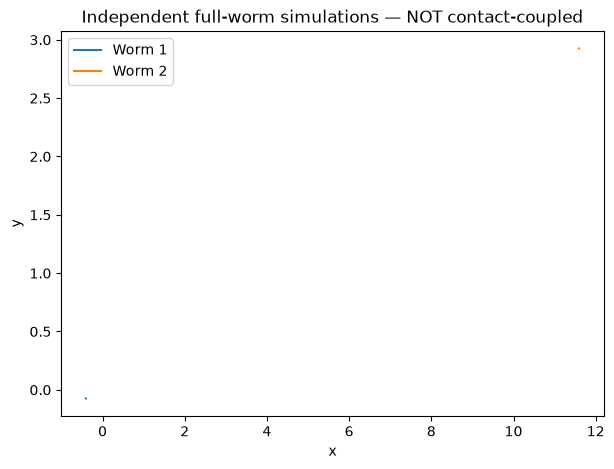

In [2]:
population=[]
for i in range(2):
    nn,body=make_worm(seed=10+i,x=12.0*i,y=3.0*i)
    ser=SerotoninModulation(concentration=1.0 if i==0 else 0.0)
    pdf=PDFR1Modulation(concentration=1.0 if i==1 else 0.0)
    population.append((nn,body,INPUTS.copy(),ser,pdf))
run=run_independent_julia_population(population,settings=SETTINGS)
print('Number of independent Julia worms:',len(run['agents']))
fig,ax=plt.subplots(figsize=(7,5))
for i,res in enumerate(run['agents']):
    ax.plot(res['x_solution'][:,0],res['y_solution'][:,0],label=f'Worm {i+1}')
ax.set(xlabel='x',ylabel='y',title='Independent full-worm simulations — NOT contact-coupled')
ax.legend();plt.show()


In [3]:
# Aggregate spatial data may be described; it is not evidence of emergent behavior.
from modWorm.behavior_analysis import population_metrics
locations=np.stack([np.column_stack((res['x_solution'].mean(axis=1),res['y_solution'].mean(axis=1)))
                    for res in run['agents']],axis=1)
print('Centroid time series shape:',locations.shape)
# Give domain_area only when a physical or model-unit area is explicitly defined.


Centroid time series shape: (4, 2, 2)


In [4]:
RUN_INTERACTING_PYTHON = False
if RUN_INTERACTING_PYTHON:
    from modWorm import shared_world
    # These are Python classes, by design; NOT the accelerated Julia classes.
    def make_python_agent(i):
        np.random.seed(20+i)
        nn = nv.CelegansWorm_NervousSystem_PPC(GAP,SYN)
        body = mb.CelegansWorm_MuscleBody_PPC(MUSCLE_MAP)
        body.initcond = body.initcond.copy()
        body.initcond[0] += 1.0*i
        nn.serotonin_modulation = SerotoninModulation(concentration=1.0 if i==0 else 0.0)
        nn.pdfr1_modulation = PDFR1Modulation(concentration=1.0 if i==1 else 0.0)
        return shared_world.WormAgent(nervous_system=nn,muscle_body=body,
                                       external_current=INPUTS.copy(),name=f'w{i}')
    a,b=make_python_agent(0),make_python_agent(1)
    time_grid=np.arange(STEPS)*a.nervous_system.timescale
    interacting=shared_world.run_shared_world([a,b],time_grid,
                          mechanical_contact=True,sensory_contact=False)
    print('Interacting contact-enabled Python run completed:',len(interacting['time']))


## Future collective Julia backend

A true accelerated interacting population requires transferring the original body-contact `coupled_body_rhs` and per-boundary sensory coupling to Julia, preserving equal/opposite pair forces and the model’s unit conventions. Independent Julia ensembles are **not** a scientifically valid substitute.